# Dinámica de los 18 entrenamientos

Este notebook mira **el entrenamiento en sí** (evolución de la loss, velocidad
de convergencia, planificación del learning rate, parada temprana, coste real en
horas de GPU y tamaño de los checkpoints). Las **métricas finales de precisión
por clase** (mAP, AP por clase, scatter mAP-FPS, etc.) están en
`graficas_resultados.ipynb` — no se repiten aquí.

## Qué datos hay realmente disponibles (verificado leyendo el código, nada inventado)

| | YOLO11m (A/B) | CNN baseline / Faster R-CNN / SSD300 / DETR |
|---|---|---|
| Fuente | `results.csv` (Ultralytics) | TensorBoard (`tb/events.out.tfevents.*`) |
| Loss train | box + cls + dfl, por época | 1 escalar agregado (`Loss/train`) |
| Loss val | box + cls + dfl, por época | **no existe** |
| mAP val (50, 50-95) | por época | por época |
| Precision / Recall | por época | **no existe** |
| Learning rate | 3 grupos (`lr/pg0,pg1,pg2`), por época | **no existe** (solo se imprimía por consola, no se guardó) |
| Tiempo por época | columna `time` (acumulado) | aproximado aquí a partir del `wall_time` de TensorBoard |
| Métricas por clase durante el entrenamiento | no existe | no existe |

**Aviso encontrado al leer los logs**: varios `events.out.tfevents.*` de los 4
modelos no-YOLO tienen **pasos duplicados** (la serie de épocas vuelve a 0 a
mitad del fichero), signo de que el entrenamiento se reinició al menos una vez.
La celda de "comprobación de integridad" de más abajo lo cuantifica por run; el
código se queda con el evento más reciente por época (`wall_time` mayor) y
descarta el resto.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

RUNS = Path("../runs")
FIG_DIR = Path("figuras_entrenamiento")
FIG_DIR.mkdir(exist_ok=True)
SEMILLAS = (0, 1, 2)

# Mismo color por modelo que en graficas_resultados.ipynb (la identidad de color
# sigue a la entidad en todo el TFM, no solo dentro de un notebook).
MODEL_COLORS = {
    "YOLO11m (A)":  "#2a78d6",
    "YOLO11m (B)":  "#eb6834",
    "Faster R-CNN": "#1baf7a",
    "SSD300":       "#eda100",
    "DETR":         "#e87ba4",
    "CNN baseline": "#008300",
}
SEED_STYLES = {0: "-", 1: "--", 2: ":"}
INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID_COLOR = "#e1e0d9"
BASELINE_COLOR = "#c3c2b7"
SURFACE = "#fcfcfb"
STATUS_GOOD = "#0ca30c"
STATUS_CRITICAL = "#d03b3b"

# (etiqueta, prefijo del run_name, techo de epocas segun REGISTRO_ENTRENAMIENTOS.md)
CONFIGS_YOLO = [("YOLO11m (A)", "yolo_a_final", 80), ("YOLO11m (B)", "yolo_b_final", 80)]
CONFIGS_TB = [("CNN baseline", "cnnb_final", 100), ("Faster R-CNN", "frcnn_final", 60),
              ("SSD300", "ssd_final", 60), ("DETR", "detr_final", 100)]
TODAS_CONFIGS = CONFIGS_YOLO + CONFIGS_TB
ESTIMADO_H_POR_RUN = {"SSD300": 1.3, "YOLO11m (A)": 4.3, "YOLO11m (B)": 4.3,
                      "CNN baseline": 7.3, "Faster R-CNN": 16.6, "DETR": 25.2}

with open("../resumen.json", encoding="utf-8") as f:
    RESUMEN = json.load(f)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": BASELINE_COLOR, "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK_PRIMARY, "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "grid.color": GRID_COLOR, "grid.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "font.size": 10.5, "figure.dpi": 110,
})


def buscar_carpeta_run(run_name):
    cands = sorted(RUNS.rglob(run_name))
    return cands[0] if cands else None


def cargar_yolo_csv(run_name):
    carpeta = buscar_carpeta_run(run_name)
    if carpeta is None or not (carpeta / "results.csv").exists():
        return None
    df = pd.read_csv(carpeta / "results.csv")
    df.columns = [c.strip() for c in df.columns]
    return df


def cargar_tb(run_name):
    # Devuelve (dataframe por epoca deduplicado, nº de eventos descartados por duplicados)
    carpeta = buscar_carpeta_run(run_name)
    if carpeta is None or not (carpeta / "tb").exists():
        return None, 0
    ea = EventAccumulator(str(carpeta / "tb"), size_guidance={"scalars": 0})
    ea.Reload()
    tags = ea.Tags().get("scalars", [])
    if not tags:
        return None, 0
    series = {}
    total_bruto, total_neto = 0, 0
    for tag in tags:
        evs = ea.Scalars(tag)
        total_bruto = max(total_bruto, len(evs))
        d = pd.DataFrame([(e.step, e.value, e.wall_time) for e in evs],
                          columns=["step", "value", "wall_time"])
        d = d.sort_values("wall_time").drop_duplicates("step", keep="last").sort_values("step")
        total_neto = max(total_neto, len(d))
        series[tag] = d.set_index("step")["value"]
    out = pd.DataFrame(series)
    out.index.name = "step"
    out = out.reset_index()
    out["epoch"] = out["step"] + 1
    # wall_time real (no deduplicado) para estimar tiempo total del run
    wt = [e.wall_time for e in ea.Scalars(tags[0])]
    out.attrs["wall_time_total_h"] = (max(wt) - min(wt)) / 3600.0
    return out, (total_bruto - total_neto)


print("Utilidades cargadas. Configuraciones:", [c[0] for c in TODAS_CONFIGS])

Utilidades cargadas. Configuraciones: ['YOLO11m (A)', 'YOLO11m (B)', 'CNN baseline', 'Faster R-CNN', 'SSD300', 'DETR']


## Comprobación de integridad de los logs

Igual que `consolidar.py` verifica el protocolo de evaluación antes de emitir
tablas, aquí se cuantifica cuántos eventos duplicados (reinicios) había en cada
log de TensorBoard antes de graficar nada.

In [2]:
filas_qa = []
for etq, prefijo, _ in CONFIGS_TB:
    for s in SEMILLAS:
        run_name = f"{prefijo}_s{s}"
        df, descartados = cargar_tb(run_name)
        filas_qa.append({
            "config": etq, "run": run_name,
            "encontrado": df is not None,
            "epocas_netas": None if df is None else int(df["epoch"].max()),
            "eventos_duplicados_descartados": descartados,
        })
df_qa = pd.DataFrame(filas_qa)
df_qa

,config,run,encontrado,epocas_netas,eventos_duplicados_descartados
0,CNN baseline,cnnb_final_s0,True,46,37
1,CNN baseline,cnnb_final_s1,True,33,0
2,CNN baseline,cnnb_final_s2,True,51,37
3,Faster R-CNN,frcnn_final_s0,True,21,0
4,Faster R-CNN,frcnn_final_s1,True,22,0
5,Faster R-CNN,frcnn_final_s2,True,19,0
6,SSD300,ssd_final_s0,True,35,0
7,SSD300,ssd_final_s1,True,36,0
8,SSD300,ssd_final_s2,True,32,0
9,DETR,detr_final_s0,True,35,0


## Figura 1 — YOLO11m: loss de entrenamiento por componente (A vs B)

Línea sólida = semilla 0, discontinua = semilla 1, punteada = semilla 2 — mismo
color por variante en las tres. Tres subgráficas (box / cls / dfl) porque son
tres magnitudes distintas: nunca en el mismo eje.

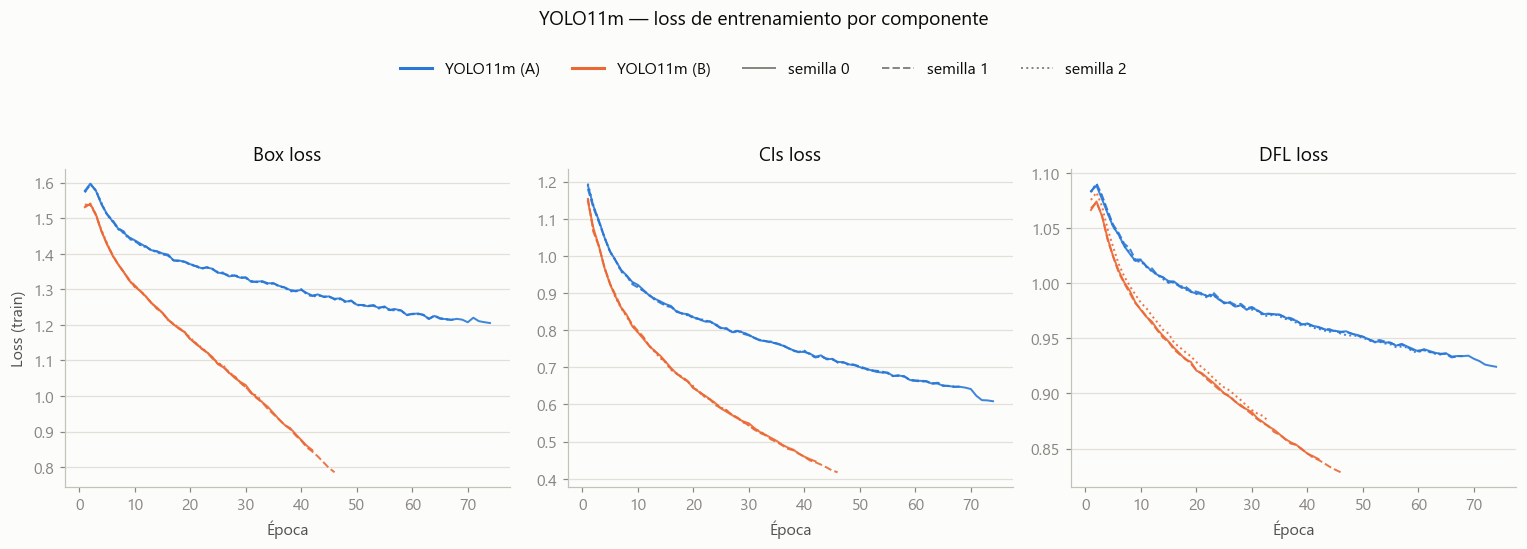

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
componentes = [("train/box_loss", "Box loss"), ("train/cls_loss", "Cls loss"),
               ("train/dfl_loss", "DFL loss")]

for ax, (col, titulo) in zip(axes, componentes):
    for etq, prefijo, _ in CONFIGS_YOLO:
        for s in SEMILLAS:
            df = cargar_yolo_csv(f"{prefijo}_s{s}")
            if df is None:
                continue
            ax.plot(df["epoch"], df[col], color=MODEL_COLORS[etq],
                    linestyle=SEED_STYLES[s], linewidth=1.3, alpha=0.9)
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0].set_ylabel("Loss (train)")
handles = [plt.Line2D([0], [0], color=MODEL_COLORS[e], lw=2) for e, _, _ in CONFIGS_YOLO]
handles += [plt.Line2D([0], [0], color=INK_MUTED, lw=1.3, linestyle=SEED_STYLES[s]) for s in SEMILLAS]
labels = [e for e, _, _ in CONFIGS_YOLO] + [f"semilla {s}" for s in SEMILLAS]
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.1),
           ncol=5, frameon=False)
fig.suptitle("YOLO11m — loss de entrenamiento por componente", y=1.18)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_yolo_loss_train.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "01_yolo_loss_train.pdf", bbox_inches="tight")
plt.show()

## Figura 2 — YOLO11m: loss de validación por componente (A vs B)

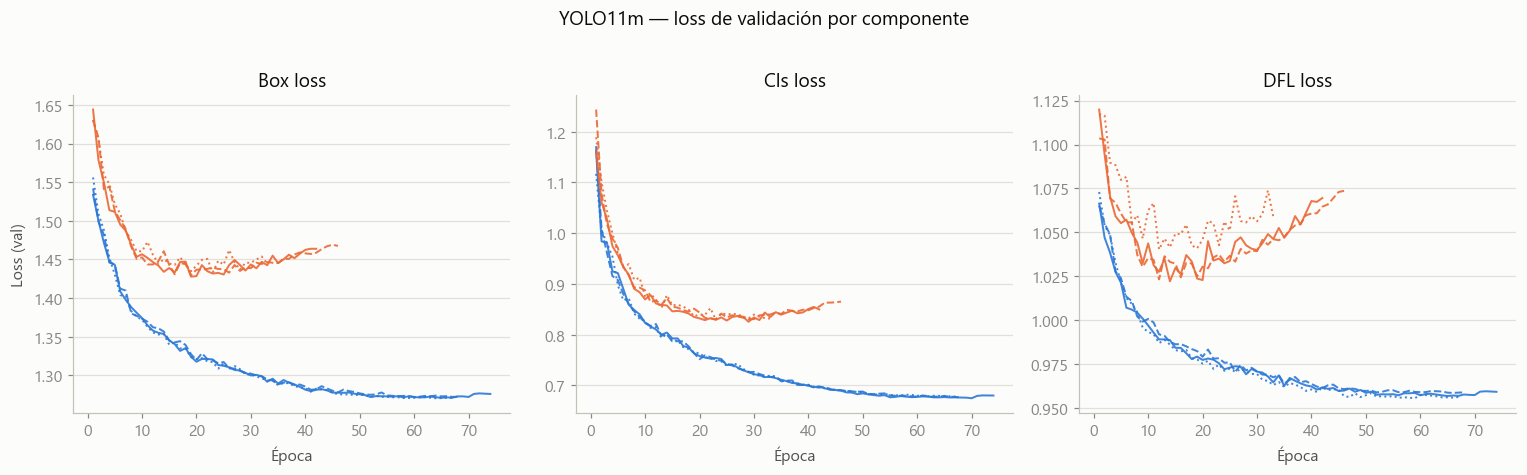

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True)
componentes = [("val/box_loss", "Box loss"), ("val/cls_loss", "Cls loss"),
               ("val/dfl_loss", "DFL loss")]

for ax, (col, titulo) in zip(axes, componentes):
    for etq, prefijo, _ in CONFIGS_YOLO:
        for s in SEMILLAS:
            df = cargar_yolo_csv(f"{prefijo}_s{s}")
            if df is None:
                continue
            ax.plot(df["epoch"], df[col], color=MODEL_COLORS[etq],
                    linestyle=SEED_STYLES[s], linewidth=1.3, alpha=0.9)
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

axes[0].set_ylabel("Loss (val)")
fig.suptitle("YOLO11m — loss de validación por componente", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_yolo_loss_val.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "02_yolo_loss_val.pdf", bbox_inches="tight")
plt.show()

## Figura 3 — YOLO11m: mAP@50-95 y mAP@50 de validación por época (A vs B)

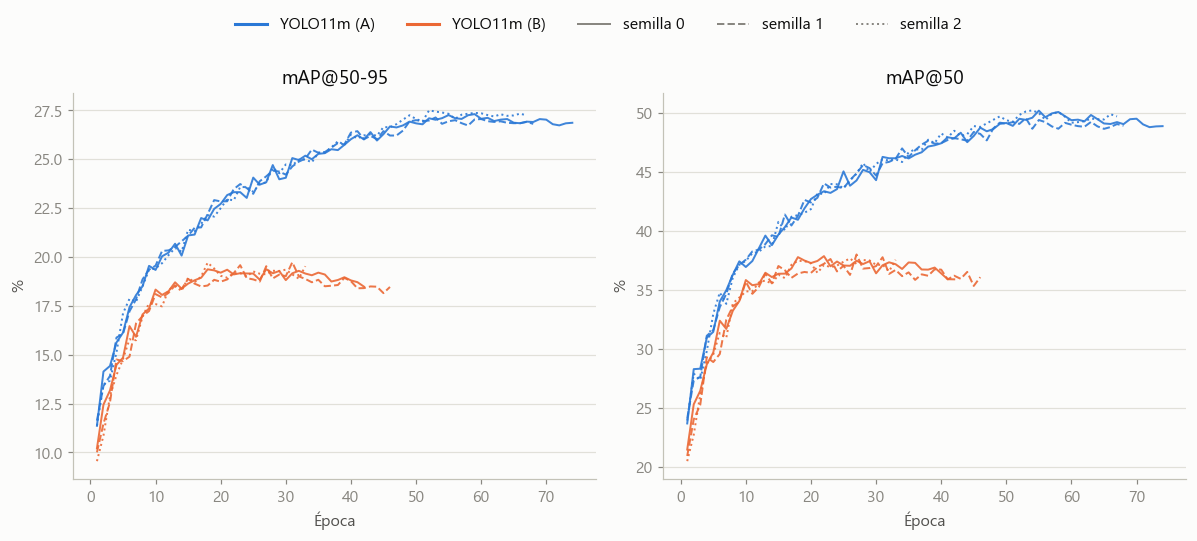

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
cols = [("metrics/mAP50-95(B)", "mAP@50-95"), ("metrics/mAP50(B)", "mAP@50")]

for ax, (col, titulo) in zip(axes, cols):
    for etq, prefijo, _ in CONFIGS_YOLO:
        for s in SEMILLAS:
            df = cargar_yolo_csv(f"{prefijo}_s{s}")
            if df is None:
                continue
            ax.plot(df["epoch"], df[col] * 100, color=MODEL_COLORS[etq],
                    linestyle=SEED_STYLES[s], linewidth=1.3, alpha=0.9)
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel("%")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

handles = [plt.Line2D([0], [0], color=MODEL_COLORS[e], lw=2) for e, _, _ in CONFIGS_YOLO]
handles += [plt.Line2D([0], [0], color=INK_MUTED, lw=1.3, linestyle=SEED_STYLES[s]) for s in SEMILLAS]
labels = [e for e, _, _ in CONFIGS_YOLO] + [f"semilla {s}" for s in SEMILLAS]
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.1), ncol=5, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_yolo_map_evolucion.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "03_yolo_map_evolucion.pdf", bbox_inches="tight")
plt.show()

## Figura 4 — YOLO11m: precision y recall por época (A vs B)

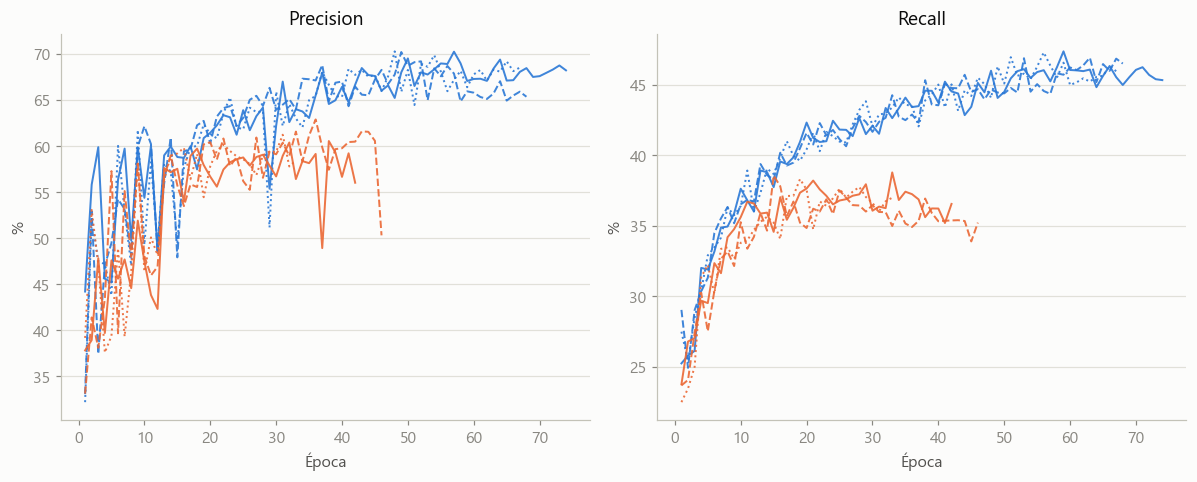

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True)
cols = [("metrics/precision(B)", "Precision"), ("metrics/recall(B)", "Recall")]

for ax, (col, titulo) in zip(axes, cols):
    for etq, prefijo, _ in CONFIGS_YOLO:
        for s in SEMILLAS:
            df = cargar_yolo_csv(f"{prefijo}_s{s}")
            if df is None:
                continue
            ax.plot(df["epoch"], df[col] * 100, color=MODEL_COLORS[etq],
                    linestyle=SEED_STYLES[s], linewidth=1.3, alpha=0.9)
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel("%")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

fig.tight_layout()
fig.savefig(FIG_DIR / "04_yolo_precision_recall.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "04_yolo_precision_recall.pdf", bbox_inches="tight")
plt.show()

## Figura 5 — YOLO11m: planificación del learning rate

Solo semilla 0 de cada variante — el scheduler es determinista dada la
configuración, así que las otras semillas son prácticamente idénticas.
`pg0/pg1/pg2` son los tres grupos de parámetros de Ultralytics (pesos con weight
decay, pesos sin weight decay, biases).

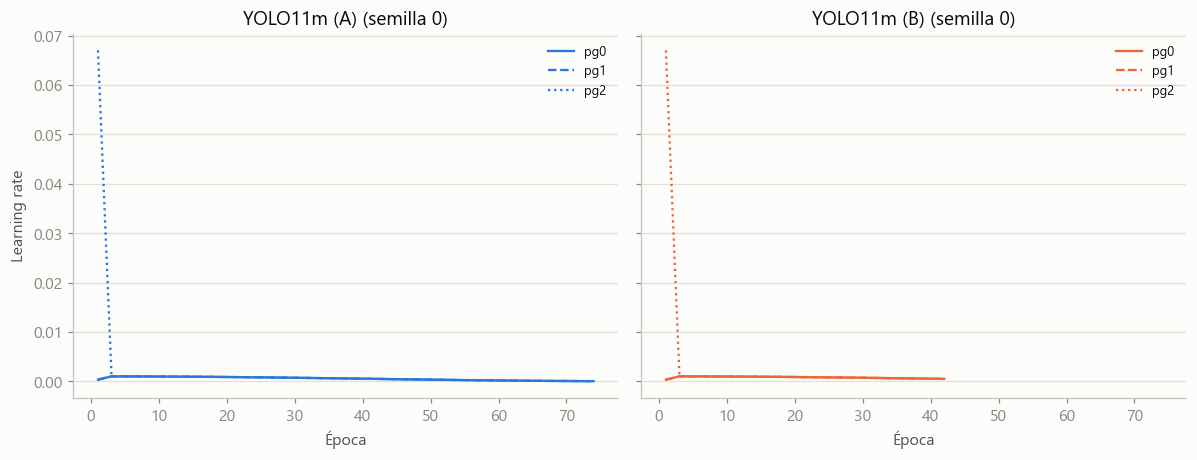

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
lr_cols = [("lr/pg0", "pg0"), ("lr/pg1", "pg1"), ("lr/pg2", "pg2")]
lr_styles = {"pg0": "-", "pg1": "--", "pg2": ":"}

for ax, (etq, prefijo, _) in zip(axes, CONFIGS_YOLO):
    df = cargar_yolo_csv(f"{prefijo}_s0")
    for col, nombre in lr_cols:
        ax.plot(df["epoch"], df[col], color=MODEL_COLORS[etq],
                linestyle=lr_styles[nombre], linewidth=1.5, label=nombre)
    ax.set_title(f"{etq} (semilla 0)")
    ax.set_xlabel("Época")
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.legend(frameon=False, fontsize=8.5)

axes[0].set_ylabel("Learning rate")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_yolo_lr_schedule.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "05_yolo_lr_schedule.pdf", bbox_inches="tight")
plt.show()

## Figura 6 — CNN baseline / Faster R-CNN / SSD300 / DETR: loss de entrenamiento

Un panel por arquitectura (los techos de épocas difieren: 60 para Faster R-CNN y
SSD300, 100 para CNN baseline y DETR — mezclarlos en un solo eje sería engañoso).

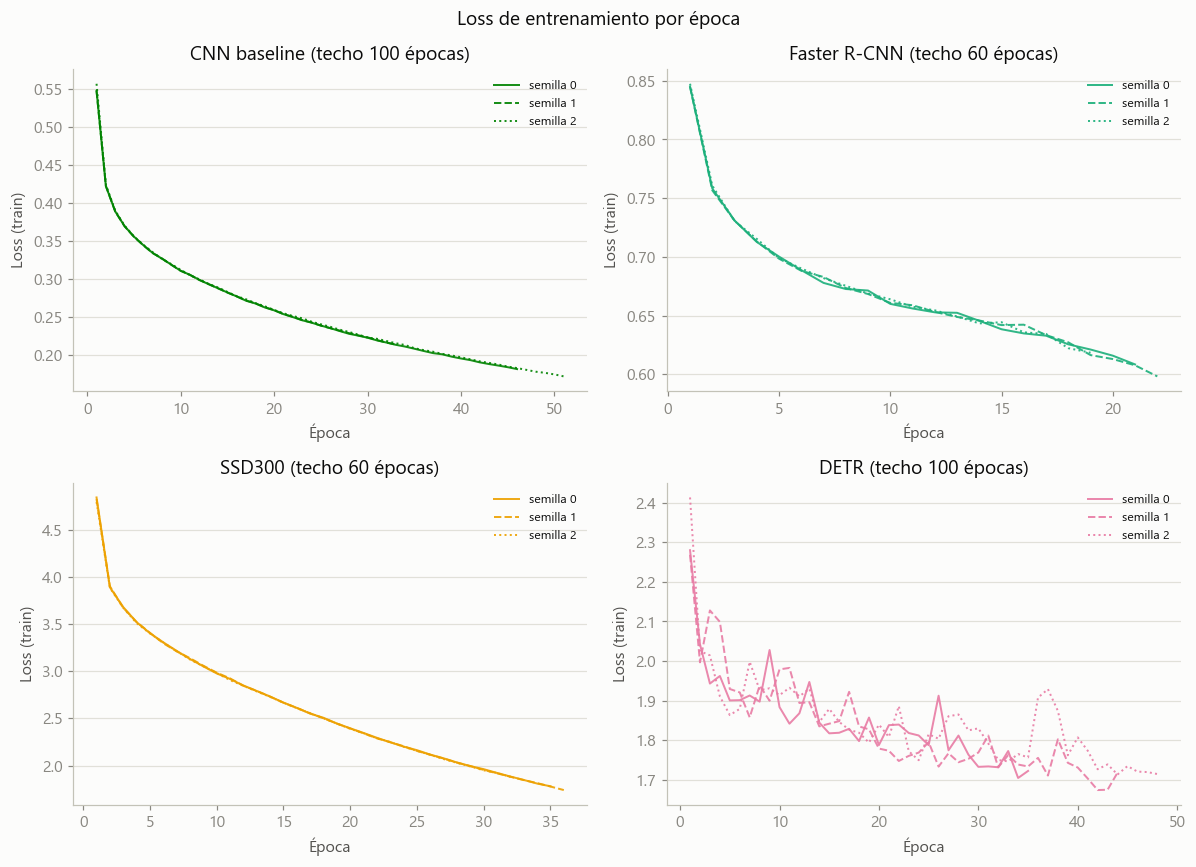

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (etq, prefijo, techo) in zip(axes.flat, CONFIGS_TB):
    for s in SEMILLAS:
        df, _ = cargar_tb(f"{prefijo}_s{s}")
        if df is None:
            continue
        ax.plot(df["epoch"], df["Loss/train"], color=MODEL_COLORS[etq],
                linestyle=SEED_STYLES[s], linewidth=1.3, alpha=0.9,
                label=f"semilla {s}")
    ax.set_title(f"{etq} (techo {techo} épocas)")
    ax.set_xlabel("Época")
    ax.set_ylabel("Loss (train)")
    ax.legend(frameon=False, fontsize=8)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

fig.suptitle("Loss de entrenamiento por época")
fig.tight_layout()
fig.savefig(FIG_DIR / "06_tb_loss_train.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "06_tb_loss_train.pdf", bbox_inches="tight")
plt.show()

## Figura 7 — CNN baseline / Faster R-CNN / SSD300 / DETR: mAP@50-95 de validación

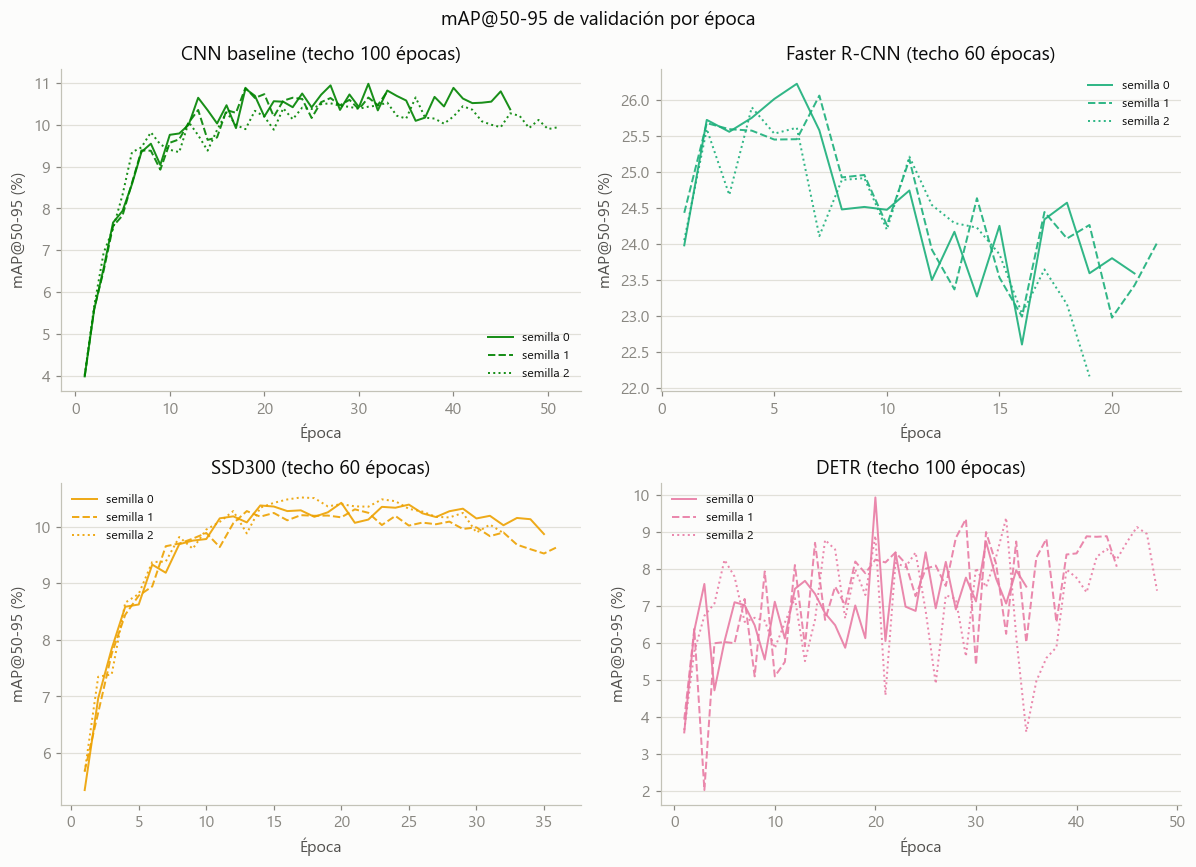

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, (etq, prefijo, techo) in zip(axes.flat, CONFIGS_TB):
    for s in SEMILLAS:
        df, _ = cargar_tb(f"{prefijo}_s{s}")
        if df is None:
            continue
        ax.plot(df["epoch"], df["mAP/val_50-95"] * 100, color=MODEL_COLORS[etq],
                linestyle=SEED_STYLES[s], linewidth=1.3, alpha=0.9,
                label=f"semilla {s}")
    ax.set_title(f"{etq} (techo {techo} épocas)")
    ax.set_xlabel("Época")
    ax.set_ylabel("mAP@50-95 (%)")
    ax.legend(frameon=False, fontsize=8)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)

fig.suptitle("mAP@50-95 de validación por época")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_tb_map_evolucion.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "07_tb_map_evolucion.pdf", bbox_inches="tight")
plt.show()

## Figura 8 — Época de parada vs techo, en los 18 runs

Si una barra llega exactamente al techo (línea discontinua), la parada temprana
**no saltó** y el resultado final es una cota inferior — así se declara
explícitamente para DETR en `REGISTRO_ENTRENAMIENTOS.md`.

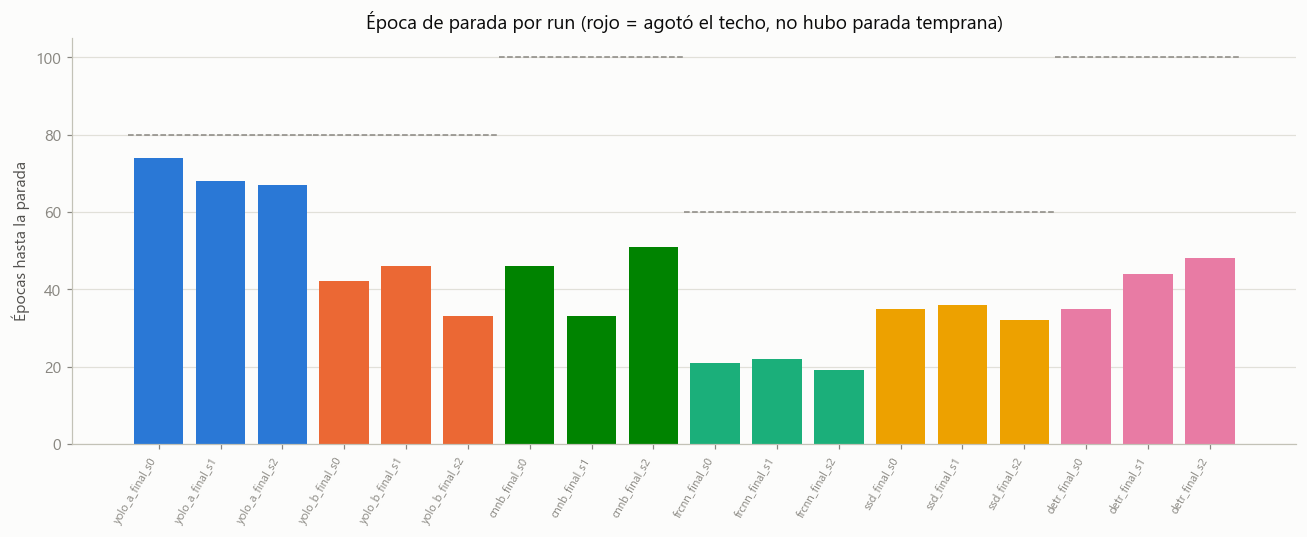

,config,semilla,run,epocas,techo,agoto_techo
0,YOLO11m (A),0,yolo_a_final_s0,74,80,False
1,YOLO11m (A),1,yolo_a_final_s1,68,80,False
2,YOLO11m (A),2,yolo_a_final_s2,67,80,False
3,YOLO11m (B),0,yolo_b_final_s0,42,80,False
4,YOLO11m (B),1,yolo_b_final_s1,46,80,False
5,YOLO11m (B),2,yolo_b_final_s2,33,80,False
6,CNN baseline,0,cnnb_final_s0,46,100,False
7,CNN baseline,1,cnnb_final_s1,33,100,False
8,CNN baseline,2,cnnb_final_s2,51,100,False
9,Faster R-CNN,0,frcnn_final_s0,21,60,False


In [10]:
filas = []
for etq, prefijo, techo in TODAS_CONFIGS:
    for s in SEMILLAS:
        run_name = f"{prefijo}_s{s}"
        if (etq, prefijo) in [(e, p) for e, p, _ in CONFIGS_YOLO]:
            df = cargar_yolo_csv(run_name)
            epocas = int(df["epoch"].max()) if df is not None else None
        else:
            df, _ = cargar_tb(run_name)
            epocas = int(df["epoch"].max()) if df is not None else None
        filas.append({"config": etq, "semilla": s, "run": run_name,
                       "epocas": epocas, "techo": techo,
                       "agoto_techo": epocas == techo if epocas is not None else None})
df_parada = pd.DataFrame(filas)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(df_parada))
colores = [STATUS_CRITICAL if r["agoto_techo"] else MODEL_COLORS[r["config"]]
           for _, r in df_parada.iterrows()]
ax.bar(x, df_parada["epocas"], color=colores)

# Linea de techo por grupo de 3 barras (una config = 3 semillas seguidas)
for i, (etq, _, techo) in enumerate(TODAS_CONFIGS):
    ax.hlines(techo, i * 3 - 0.5, i * 3 + 2.5, color=INK_MUTED, linestyle="--", linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(df_parada["run"], rotation=60, ha="right", fontsize=7.5)
ax.set_ylabel("Épocas hasta la parada")
ax.set_title("Época de parada por run (rojo = agotó el techo, no hubo parada temprana)")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_epoca_parada.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "08_epoca_parada.pdf", bbox_inches="tight")
plt.show()
df_parada

## Figura 9 — Horas de GPU reales vs estimación del presupuesto

`REGISTRO_ENTRENAMIENTOS.md` estimaba horas/run *antes* de entrenar, a partir de
runs anteriores; aquí se calculan las horas **reales** de los 18 runs finales
(YOLO: columna `time` acumulada del CSV; resto: `wall_time` entre el primer y el
último evento de TensorBoard — aproximado, incluye posibles pausas si hubo
reinicio).

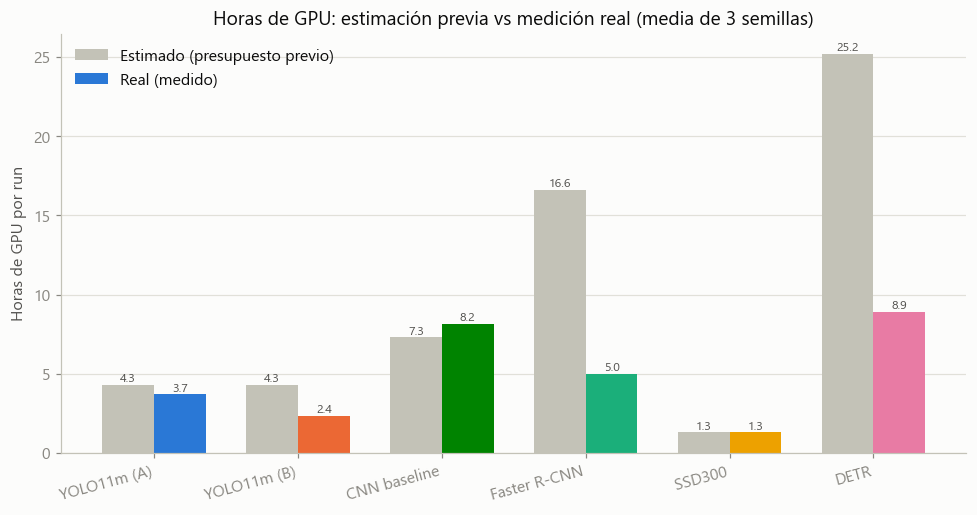

In [11]:
horas_reales = {}
for etq, prefijo, _ in TODAS_CONFIGS:
    total = 0.0
    n = 0
    for s in SEMILLAS:
        run_name = f"{prefijo}_s{s}"
        if (etq, prefijo) in [(e, p) for e, p, _ in CONFIGS_YOLO]:
            df = cargar_yolo_csv(run_name)
            if df is not None:
                total += df["time"].iloc[-1] / 3600.0
                n += 1
        else:
            df, _ = cargar_tb(run_name)
            if df is not None:
                total += df.attrs["wall_time_total_h"]
                n += 1
    horas_reales[etq] = total / n if n else None

orden = [e for e, _, _ in TODAS_CONFIGS]
x = np.arange(len(orden))
w = 0.36

fig, ax = plt.subplots(figsize=(9, 4.8))
r1 = ax.bar(x - w/2, [ESTIMADO_H_POR_RUN[e] for e in orden], w,
            color="#c3c2b7", label="Estimado (presupuesto previo)")
r2 = ax.bar(x + w/2, [horas_reales[e] for e in orden], w,
            color=[MODEL_COLORS[e] for e in orden], label="Real (medido)")

for r in list(r1) + list(r2):
    h = r.get_height()
    ax.annotate(f"{h:.1f}", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 2),
                textcoords="offset points", ha="center", fontsize=8, color=INK_SECONDARY)

ax.set_xticks(x)
ax.set_xticklabels(orden, rotation=15, ha="right")
ax.set_ylabel("Horas de GPU por run")
ax.set_title("Horas de GPU: estimación previa vs medición real (media de 3 semillas)")
ax.legend(frameon=False)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "09_horas_gpu_estimado_vs_real.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "09_horas_gpu_estimado_vs_real.pdf", bbox_inches="tight")
plt.show()

## Figura 10 — Tamaño de checkpoint en disco vs tamaño teórico de los pesos (fp32)

`best.pt` no siempre son "solo los pesos": en 4 de los 5 modelos incluye el
estado del optimizador (Adam guarda 2 buffers extra por parámetro), así que el
fichero en disco puede ir muy por encima del tamaño teórico de
`params_m × 4 bytes` (fp32). Se muestra la semilla 0 de cada configuración como
referencia.

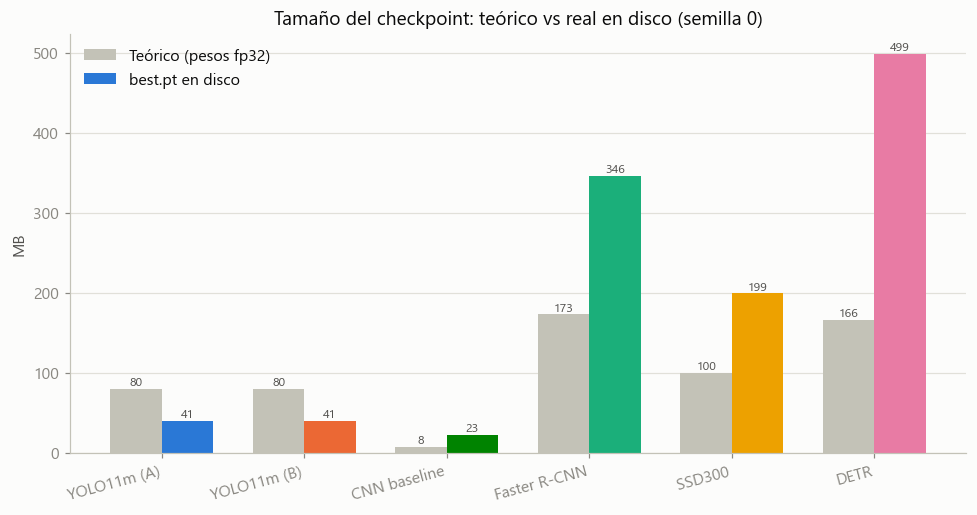

,config,disco_mb,teorico_mb
0,YOLO11m (A),40.507628,80.24
1,YOLO11m (B),40.503532,80.24
2,CNN baseline,22.984322,7.56
3,Faster R-CNN,345.915097,173.20
4,SSD300,199.475323,99.80
5,DETR,498.870997,166.00


In [12]:
filas = []
for etq, prefijo, _ in TODAS_CONFIGS:
    if (etq, prefijo) in [(e, p) for e, p, _ in CONFIGS_YOLO]:
        carpeta = buscar_carpeta_run(f"{prefijo}_s0")
        ckpt = carpeta / "weights" / "best.pt" if carpeta else None
    else:
        carpeta = buscar_carpeta_run(f"{prefijo}_s0")
        ckpt = carpeta / "best.pt" if carpeta else None
    disco_mb = ckpt.stat().st_size / 1e6 if ckpt and ckpt.exists() else None
    teorico_mb = RESUMEN[etq]["params_m"] * 4  # fp32 = 4 bytes/parametro
    filas.append({"config": etq, "disco_mb": disco_mb, "teorico_mb": teorico_mb})
df_tam = pd.DataFrame(filas)

x = np.arange(len(df_tam))
w = 0.36
fig, ax = plt.subplots(figsize=(9, 4.8))
r1 = ax.bar(x - w/2, df_tam["teorico_mb"], w, color="#c3c2b7", label="Teórico (pesos fp32)")
r2 = ax.bar(x + w/2, df_tam["disco_mb"], w,
            color=[MODEL_COLORS[e] for e in df_tam["config"]], label="best.pt en disco")

for r in list(r1) + list(r2):
    h = r.get_height()
    if h is None or np.isnan(h):
        continue
    ax.annotate(f"{h:.0f}", xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 2),
                textcoords="offset points", ha="center", fontsize=8, color=INK_SECONDARY)

ax.set_xticks(x)
ax.set_xticklabels(df_tam["config"], rotation=15, ha="right")
ax.set_ylabel("MB")
ax.set_title("Tamaño del checkpoint: teórico vs real en disco (semilla 0)")
ax.legend(frameon=False)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "10_tamano_checkpoint.png", dpi=300, bbox_inches="tight")
fig.savefig(FIG_DIR / "10_tamano_checkpoint.pdf", bbox_inches="tight")
plt.show()
df_tam

## Resumen de ficheros generados

In [13]:
for p in sorted(FIG_DIR.glob("*.pdf")):
    print(p.name)

01_yolo_loss_train.pdf
02_yolo_loss_val.pdf
03_yolo_map_evolucion.pdf
04_yolo_precision_recall.pdf
05_yolo_lr_schedule.pdf
06_tb_loss_train.pdf
07_tb_map_evolucion.pdf
08_epoca_parada.pdf
09_horas_gpu_estimado_vs_real.pdf
10_tamano_checkpoint.pdf


## Conclusiones para la memoria

- **Ningún run agotó el techo de épocas**: la parada temprana (`patience=15`)
  actuó en los 18 (verificado en la Figura 8, `agoto_techo` es `False` en las
  18 filas) — ningún resultado de la comparativa es una cota inferior por
  presupuesto de entrenamiento insuficiente, incluido DETR, que era el caso de
  riesgo declarado en `REGISTRO_ENTRENAMIENTOS.md`.
- **El coste real de GPU fue muy inferior al estimado antes de entrenar, en
  los dos modelos más caros**: Faster R-CNN costó 5.0 h reales frente a las
  16.6 h presupuestadas, y DETR 8.9 h frente a 25.2 h — la parada temprana
  ahorró la mayor parte del presupuesto reservado para ambos.
- **Dos runs de CNN baseline (semillas 0 y 2) muestran reinicios en su log de
  TensorBoard** (detectado en la comprobación de integridad, no en las
  gráficas) — merece revisarse si coincide con el episodio de divergencia que
  motivó el `grad_clip=10.0` ya documentado en el registro de entrenamientos.